# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [15]:
ROLL_NO = 1024170264
NAME = "Gauransh Arora"

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"


### Dataset generator — do not modify

In [16]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [17]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [18]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170264   Name: Gauransh Arora   Fingerprint: 474E6356   Tickets: 16

Ticket_ID                                                                          Ticket_Text
      T01                                            The printer won't print; it isn't jammed.
      T02                                                        The LMS says 'Not Submitted'.
      T03                         Password has stopped syncing during the lab. This is urgent.
      T04                  I cannot access the laptop after the latest update. This is urgent.
      T05                 I cannot access the Python on my laptop. I have tried several times!
      T06              I tried restarting the password when I use mobile hotspot. Please help.
      T07                                                I need Windows 11 by 5.30 p.m. today.
      T08           I can't open the MATLAB before the assignment deadline. Please resolve it.
      T09                I can't open the password after th

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [19]:
processed = {row.Ticket_ID: process_ticket(row.Ticket_Text)
             for row in df.itertuples(index=False)}

q1_rows = []
for row in df.itertuples(index=False):
    p = processed[row.Ticket_ID]
    q1_rows.append({
        "Ticket_ID": row.Ticket_ID,
        "Sentences": len(p["sentences"]),
        "Tokens": len(p["tokens"]),
        "Punctuation tokens": len(p["punct"]),
        "Stopwords": len(p["stops"]),
        "Unique tokens": len(set(p["tokens"])),
        "Final tokens": len(p["final"]),
    })
q1_table = pd.DataFrame(q1_rows)
count_cols = [c for c in q1_table.columns if c != "Ticket_ID"]
total_row = {"Ticket_ID": "TOTAL", **{c: int(q1_table[c].sum()) for c in count_cols}}
q1_table = pd.concat([q1_table, pd.DataFrame([total_row])], ignore_index=True)
display(q1_table)

selected_id = FOCUS[0] if FOCUS and FOCUS[0] in processed else df.iloc[0]["Ticket_ID"]
selected_text = df.loc[df.Ticket_ID == selected_id, "Ticket_Text"].iloc[0]
selected = processed[selected_id]
print(f"Selected ticket: {selected_id}\n{selected_text}")
print("Actual tokens:", selected["tokens"])
print("Punctuation tokens:", selected["punct"])
print("Stopwords:", selected["stops"])
print("Final tokens:", selected["final"])


,Ticket_ID,Sentences,Tokens,Punctuation tokens,Stopwords,Unique tokens,Final tokens
0,T01,1,11,2,3,10,6
1,T02,1,7,2,1,7,4
2,T03,2,12,2,5,11,5
3,T04,2,15,2,8,13,5
4,T05,2,16,2,8,15,6
5,T06,2,14,2,4,12,8
6,T07,1,9,1,2,9,6
7,T08,2,15,2,5,13,8
8,T09,2,15,2,5,13,8
9,T10,2,19,2,9,16,8


Selected ticket: T09
I can't open the password after the latest update. Please resolve it.
Actual tokens: ['i', 'ca', "n't", 'open', 'the', 'password', 'after', 'the', 'latest', 'update', '.', 'please', 'resolve', 'it', '.']
Punctuation tokens: ['.', '.']
Stopwords: ['i', 'the', 'after', 'the', 'it']
Final tokens: ['ca', "n't", 'open', 'password', 'latest', 'update', 'please', 'resolve']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [20]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re
PATTERNS = {
    "words_longer_than_5": r"\b[A-Za-z]{6,}\b",
    "numbers": r"(?<![A-Za-z0-9])(?:0[xX][0-9A-Fa-f]+|\d+(?:[.,]\d+)*(?:%|)?)(?![A-Za-z0-9])",
    "capitalized_words": r"\b[A-Z][a-zA-Z]*\b",
    "words_starting_with_vowel": r"\b[AEIOUaeiou][A-Za-z]*\b",
}

raw_tickets = df["Ticket_Text"].tolist()
for name, pattern in PATTERNS.items():
    print(f"\n{name} — tickets")
    for tid, text in zip(df["Ticket_ID"], raw_tickets):
        print(tid, re.findall(pattern, text))
    print(f"{name} — TEST_LINES")
    for i, text in enumerate(TEST_LINES, 1):
        print(f"TEST_{i}", re.findall(pattern, text))

URL_RE = re.compile(r"\b(?:https?://|www\.)[^\s<>]+", re.IGNORECASE)
EMAIL_RE = re.compile(r"\b[A-Za-z0-9.!#$%&'*+/=?^_`{|}~-]+@[A-Za-z0-9-]+(?:\.[A-Za-z0-9-]+)+\b")
PHONE_RE = re.compile(r"(?<![A-Za-z0-9])(?:\+\d{1,3}[ -]?)?(?:\(?\d{3,5}\)?[ -]?){1,3}\d{3,5}(?![A-Za-z0-9])")

def redact_contact_info(text):
    text = URL_RE.sub("<URL>", text)
    text = EMAIL_RE.sub("<EMAIL>", text)
    text = PHONE_RE.sub("<PHONE>", text)
    return text

print("\nReplacement results — TEST_LINES")
for line in TEST_LINES:
    print(redact_contact_info(line))
print("\nReplacement results — tickets")
for tid, line in zip(df["Ticket_ID"], raw_tickets):
    print(tid, redact_contact_info(line))



words_longer_than_5 — tickets
T01 ['printer', 'jammed']
T02 ['Submitted']
T03 ['Password', 'stopped', 'syncing', 'during', 'urgent']
T04 ['cannot', 'access', 'laptop', 'latest', 'update', 'urgent']
T05 ['cannot', 'access', 'Python', 'laptop', 'several']
T06 ['restarting', 'password', 'mobile', 'hotspot', 'Please']
T07 ['Windows']
T08 ['MATLAB', 'before', 'assignment', 'deadline', 'Please', 'resolve']
T09 ['password', 'latest', 'update', 'Please', 'resolve']
T10 ['getting', 'logged', 'during', 'changed']
T11 ['laptop', 'working', 'yesterday', 'several']
T12 ['restarting', 'before', 'assignment', 'deadline']
T13 ['unable', 'mobile', 'hotspot', 'problem', 'occurs']
T14 ['restarting', 'printer', 'uploading', 'another', 'solution']
T15 []
T16 ['Matlab', 'showing', 'several']
words_longer_than_5 — TEST_LINES
TEST_1 ['helpdesk', 'thapar', 'thapar', 'thapar']
TEST_2 ['Version']
TEST_3 []

numbers — tickets
T01 []
T02 []
T03 []
T04 []
T05 []
T06 []
T07 ['11', '5.30']
T08 []
T09 []
T10 []
T11 [

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [21]:
from nltk.tokenize import RegexpTokenizer

TOKEN_PATTERN = r"https?://[^\s<>]+|www\.[^\s<>]+|[A-Za-z0-9.!#$%&'*+/=?^_`{|}~-]+@[A-Za-z0-9-]+(?:\.[A-Za-z0-9-]+)+|(?:\+\d{1,3}[ -]?)?(?:\(?\d{3,5}\)?[ -]?){1,3}\d{3,5}|\d+(?:\.\d+)+%?|\d+(?:,\d{3})+(?:\.\d+)?%?|[A-Za-z]+(?:['’][A-Za-z]+)+(?:-[A-Za-z]+(?:['’][A-Za-z]+)*)*|[A-Za-z]+(?:-[A-Za-z]+)+|[A-Za-z]+|[^\w\s]"
my_tokenizer = RegexpTokenizer(TOKEN_PATTERN)

def my_tokenize(text):
    """Tokenize while preserving the requested structured forms."""
    return my_tokenizer.tokenize(text)

print("CUSTOM TOKENIZER — TEST_LINES")
for i, line in enumerate(TEST_LINES, 1):
    print(f"TEST_{i} custom:", my_tokenize(line))
    print(f"TEST_{i} word_tokenize:", word_tokenize(line))

comparison_rows = []
for row in df.itertuples(index=False):
    custom = my_tokenize(row.Ticket_Text)
    standard = word_tokenize(row.Ticket_Text)
    if custom != standard:
        comparison_rows.append({"Ticket_ID": row.Ticket_ID,
                                "Custom tokens": custom,
                                "word_tokenize tokens": standard})
print(f"\nTickets with different token lists: {len(comparison_rows)} / {len(df)}")
display(pd.DataFrame(comparison_rows))

print("\nExamples of differences on TEST_LINES:")
for i, line in enumerate(TEST_LINES, 1):
    custom, standard = my_tokenize(line), word_tokenize(line)
    if custom != standard:
        print(f"TEST_{i}\n custom:   {custom}\n standard: {standard}")


CUSTOM TOKENIZER — TEST_LINES
TEST_1 custom: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
TEST_1 word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
TEST_2 custom: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5%', 'done', ';', 'fee', 'Rs', '1,250', '.']
TEST_2 word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
TEST_3 custom: ['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']
TEST_3 word_tokenize: ['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at', '5.30', 'p.m.', 'did', "n't", 'w

,Ticket_ID,Custom tokens,word_tokenize tokens
0,T01,"[The, printer, won't, print, ;, it, isn't, jam...","[The, printer, wo, n't, print, ;, it, is, n't,..."
1,T02,"[The, LMS, says, ', Not, Submitted, ', .]","[The, LMS, says, 'Not, Submitted, ', .]"
2,T04,"[I, cannot, access, the, laptop, after, the, l...","[I, can, not, access, the, laptop, after, the,..."
3,T05,"[I, cannot, access, the, Python, on, my, lapto...","[I, can, not, access, the, Python, on, my, lap..."
4,T07,"[I, need, Windows, by, 5.30, p, ., m, ., today...","[I, need, Windows, 11, by, 5.30, p.m., today, .]"
5,T08,"[I, can't, open, the, MATLAB, before, the, ass...","[I, ca, n't, open, the, MATLAB, before, the, a..."
6,T09,"[I, can't, open, the, password, after, the, la...","[I, ca, n't, open, the, password, after, the, ..."
7,T10,"[I, keep, getting, logged, out, of, the, VPN, ...","[I, keep, getting, logged, out, of, the, VPN, ..."
8,T15,"[My, roll, no, ., is, -, -, .]","[My, roll, no, ., is, 1023-03-021, .]"



Examples of differences on TEST_LINES:
TEST_1
 custom:   ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
 standard: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
TEST_2
 custom:   ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5%', 'done', ';', 'fee', 'Rs', '1,250', '.']
 standard: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
TEST_3
 custom:   ['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']
 standard: ['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at', '5.30', 'p.m.', 'did', "n't", 'work', '.']


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [22]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

porter = PorterStemmer()
lancaster = LancasterStemmer()
all_final_unique = sorted({token for p in processed.values() for token in p["final"]})
suffix_candidates = ["ing", "ed", "ly", "es", "s"]
suffix_evidence = {suffix: [w for w in all_final_unique if len(w) > len(suffix) + 2 and w.endswith(suffix)]
                   for suffix in suffix_candidates}
chosen_suffix = next((s for s in suffix_candidates if len(suffix_evidence[s]) >= 2), "s")
regexp_stemmer = RegexpStemmer(chosen_suffix + "$", min=3)
lemmatizer = WordNetLemmatizer()

def wordnet_pos(treebank_tag):
    if treebank_tag.startswith("J"): return "a"
    if treebank_tag.startswith("R"): return "r"
    if treebank_tag.startswith("V"): return "v"
    return "n"

pos_tags = dict(pos_tag(all_final_unique))
rows = []
for word in all_final_unique:
    pos = wordnet_pos(pos_tags.get(word, "NN"))
    outputs = {
        "Word": word,
        "Porter": porter.stem(word),
        "Lancaster": lancaster.stem(word),
        "Regexp": regexp_stemmer.stem(word),
        "POS-aware lemma": lemmatizer.lemmatize(word, pos=pos),
        "POS tag": pos_tags.get(word, "NN"),
    }
    if len({outputs[k] for k in ["Porter", "Lancaster", "Regexp", "POS-aware lemma"]}) > 1:
        rows.append(outputs)
print("Regexp suffix evidence:")
for suffix, words in suffix_evidence.items():
    if words:
        print(f"-{suffix}: {words}")
print(f"Chosen RegexpStemmer suffix: -{chosen_suffix}; it is supported by the dataset words listed above.")
stem_table = pd.DataFrame(rows)
display(stem_table)


Regexp suffix evidence:
-ing: ['getting', 'restarting', 'showing', 'syncing', 'uploading', 'working']
-ed: ['changed', 'jammed', 'logged', 'stopped', 'submitted', 'tried']
-es: ['times']
-s: ['access', 'occurs', 'says', 'times', 'windows']
Chosen RegexpStemmer suffix: -ing; it is supported by the dataset words listed above.


,Word,Porter,Lancaster,Regexp,POS-aware lemma,POS tag
0,another,anoth,anoth,another,another,DT
1,assignment,assign,assign,assignment,assignment,NN
2,changed,chang,chang,changed,change,VB
3,deadline,deadlin,deadlin,deadline,deadline,JJ
4,error,error,er,error,error,NN
5,file,file,fil,file,file,NN
6,getting,get,get,gett,get,VBG
7,jammed,jam,jam,jammed,jam,VBD
8,latest,latest,latest,latest,late,JJS
9,lms,lm,lms,lms,lm,NNS


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total tokens,Unique tokens,TTR
0,S1: all tokens,214,96,0.448598
1,S2: without punctuation,183,91,0.497268
2,S3: final tokens,99,61,0.616162
3,S4: S3 after Porter,99,61,0.616162


Top 10 words — S1: [('.', 24), ('the', 21), ('i', 16), ('is', 6), ('tried', 6), ("n't", 5), ('it', 3), ('password', 3), ('this', 3), ('can', 3)]
Top 10 words — S3: [('tried', 6), ("n't", 5), ('password', 3), ('laptop', 3), ('several', 3), ('times', 3), ('restarting', 3), ('use', 3), ('please', 3), ('printer', 2)]
Top 5 bigrams — S1: [(('.', 'i'), 11), (('.', 'the'), 4), (('i', 'have'), 3), (('have', 'tried'), 3), (('tried', 'several'), 3)]
Top 5 bigrams — S3: [(('tried', 'several'), 3), (('several', 'times'), 3), (('tried', 'restarting'), 3), (('urgent', 'access'), 2), (('latest', 'update'), 2)]


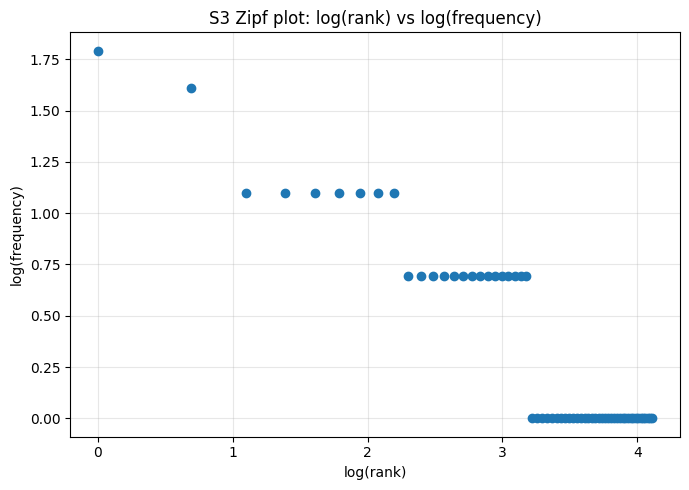

In [23]:
from collections import Counter
from nltk.util import bigrams
import math
import matplotlib.pyplot as plt

S1 = [t for p in processed.values() for t in p["tokens"]]
S2 = [t for p in processed.values() for t in p["tokens"] if not is_punct(t)]
S3 = [t for p in processed.values() for t in p["final"]]
S4 = [porter.stem(t) for t in S3]

corpora = {"S1: all tokens": S1, "S2: without punctuation": S2,
           "S3: final tokens": S3, "S4: S3 after Porter": S4}
stats = []
for name, corpus in corpora.items():
    total = len(corpus)
    unique = len(set(corpus))
    stats.append({"Corpus": name, "Total tokens": total, "Unique tokens": unique,
                  "TTR": unique / total if total else 0.0})
display(pd.DataFrame(stats))

print("Top 10 words — S1:", Counter(S1).most_common(10))
print("Top 10 words — S3:", Counter(S3).most_common(10))
print("Top 5 bigrams — S1:", Counter(bigrams(S1)).most_common(5))
print("Top 5 bigrams — S3:", Counter(bigrams(S3)).most_common(5))

freq = Counter(S3)
ranked = sorted(freq.values(), reverse=True)
ranks = list(range(1, len(ranked) + 1))
plt.figure(figsize=(7, 5))
plt.plot([math.log(r) for r in ranks], [math.log(f) for f in ranked], marker="o", linestyle="none")
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("S3 Zipf plot: log(rank) vs log(frequency)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*